<!-- CURRICULUM_HEADER_START -->
<div class="mh"><p class="mh-crumb"><a href="/series/statistics/index.html">Statistics</a><span class="sep">·</span>Part 3 · Resampling</p><p class="mh-facts"><span class="lvl lvl-intermediate">Intermediate</span></p><p class="mh-assumes">Assumes <a href="/blogs/variance-and-standard-error.html">Variance and standard error</a>.</p></div>
<!-- CURRICULUM_HEADER_END -->

::: {.callout-note appearance="simple" icon=false}
## TL;DR

The bootstrap measures how much a statistic would change between samples using only the sample you have: draw rows with replacement, recompute the statistic, repeat a few thousand times, and read the spread of the results. It needs no formula, so it puts intervals on medians, ratios and a model's RMSE. It is not automatic. On skewed synthetic order sizes, nominal 95% intervals for the mean covered the truth in $80\%$ of samples of 10, and intervals for the standard deviation in $38\%$. Rows that share a bush, a farm or a run of weeks break it: resampling berries instead of bushes covered $79\%$, and resampling validation rows instead of farms covered $68\%$ for the gap between two models' RMSEs. Resample whole groups or blocks, score both models on the same resample, and with only about ten groups expect intervals that are still too short.

Before bootstrapping, ask what was sampled independently, and resample that.
:::

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from scipy.signal import lfilter

# fallcolor is the site's colour module in tools/, not an installed package.
here = [Path.cwd(), *Path.cwd().parents]
sys.path.insert(0, str(next(p / "tools" for p in here if (p / "tools/fallcolor.py").exists())))
import fallcolor

fallcolor.palette.use("default")
plt.rcParams["figure.dpi"] = 110
C1, C2, C3, C4 = fallcolor.palette.discrete("default")
B = 2000  # bootstrap resamples, unless a cell says otherwise

[Variance and standard error](../variance-and-standard-error.qmd) gave a formula for the standard error of a mean, and [Confidence intervals](../confidence-intervals.qmd) turned it into an interval. A median, a ratio of two totals or a model's RMSE has no such formula. The bootstrap, introduced by Efron in 1979, estimates their sampling variation from the data alone; his first examples included the variance of a sample median and ratio estimation[^1]. Efron and Tibshirani's textbook is a book-length treatment[^2].

## Resample the data, recompute the statistic

Treat the sample as a stand-in for the population. Each **resample** has the same size $n$ as the data and is drawn **with replacement**, so some rows appear twice and others not at all. Compute the statistic on each of $B$ resamples; the spread of these **replicates** stands in for the spread across fresh samples, and their standard deviation is the **bootstrap standard error**.

The example is **synthetic**: weekly orders from 30 stores, in cases, from a strongly skewed (lognormal) distribution with true median 40 and true mean $40\,e^{0.5} = 65.9$ cases.

In [2]:
rng = np.random.default_rng(0)
orders = 40 * rng.lognormal(0, 1, 30)  # synthetic: 30 stores' weekly orders (cases); true median 40
resamples = orders[rng.integers(0, 30, (B, 30))]  # B rows of 30, each drawn with replacement
med, med_star = np.median(orders), np.median(resamples, axis=1)
lo, hi = np.quantile(med_star, [0.025, 0.975])
print(f"median {med:.1f} cases, bootstrap SE {med_star.std(ddof=1):.1f}")
print(f"95% percentile interval {lo:.1f} to {hi:.1f}; basic interval {2 * med - hi:.1f} to {2 * med - lo:.1f}")
print(f"mean {orders.mean():.1f}: bootstrap SE {resamples.mean(axis=1).std(ddof=1):.2f}, "
      f"s/sqrt(n) {orders.std(ddof=1) / np.sqrt(30):.2f}")

median 35.1 cases, bootstrap SE 7.0
95% percentile interval 23.3 to 47.6; basic interval 22.6 to 46.9
mean 48.0: bootstrap SE 7.20, s/sqrt(n) 7.20


The median is $35.1$ cases, with a bootstrap standard error of $7.0$. For the mean, where a formula exists, the bootstrap gives $7.20$, the same as $s/\sqrt{n}$.

Two common ways turn replicates into a 95% interval. Write $\hat{\theta}$ for the statistic on the data and $q_{0.025}$, $q_{0.975}$ for the 2.5th and 97.5th percentiles of the replicates, in the statistic's units.

- **Percentile interval**: $[\,q_{0.025},\ q_{0.975}\,]$, the middle 95% of the replicates.
- **Basic interval**: $[\,2\hat{\theta} - q_{0.975},\ 2\hat{\theta} - q_{0.025}\,]$, the percentiles reflected about $\hat{\theta}$.

They agree when the replicates are symmetric, as nearly here: $23.3$ to $47.6$ cases by percentile, $22.6$ to $46.9$ by basic.

::: {.callout-note collapse="true"}
## Why the basic interval reflects the percentiles

It assumes the bootstrap error $\theta^{*} - \hat{\theta}$ of a replicate $\theta^{*}$ behaves like the real error $\hat{\theta} - \theta$, with $\theta$ the true value; solving for $\theta$ flips the percentiles. A long right tail in the replicates becomes a long left tail in the interval.
:::

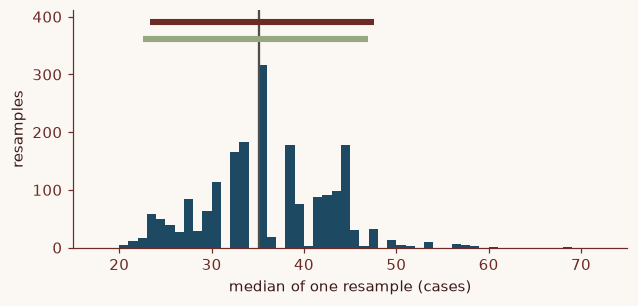

In [3]:
fig, ax = plt.subplots(figsize=(6.5, 2.8))
ax.hist(med_star, bins=np.arange(15, 75, 1), color=C1)
ax.margins(y=0.3)
ax.axvline(med, color="0.3", lw=1.5)
for (a, b), c, y in [((lo, hi), C3, 0.95), ((2 * med - hi, 2 * med - lo), C4, 0.88)]:
    ax.plot([a, b], [y, y], color=c, lw=4, transform=ax.get_xaxis_transform(), solid_capstyle="butt")
ax.set(xlabel="median of one resample (cases)", ylabel="resamples", xlim=(15, 75))
plt.show()

**Figure 1 | Bootstrap distribution of a median.** 2000 resampled medians of 30 synthetic orders. Grey, the sample median; bars, percentile (upper) and basic (lower) intervals.

## When the intervals fall short

To learn how good a bootstrap interval is, run it where the truth is known. Here, 1000 synthetic datasets each of 10, 30 and 100 orders from the same distribution got nominal 95% intervals for the mean, median and standard deviation. **BCa** (bias-corrected and accelerated) shifts and stretches the percentiles to allow for bias and skew in the replicates[^3]; the call is `scipy.stats.bootstrap((x,), np.median, method="BCa")`. The findings first:

- **Median: the percentile interval is fine**, $91.9\%$ to $94.4\%$. The basic interval is not ($79.7\%$ at $n = 10$).
- **Mean, small skewed samples: all three undercover**, $79.9\%$ at $n = 10$ by percentile, rising to $92.0\%$ at 100. Our explanation, untested: ten orders rarely include the rare large ones that drive the mean, and resampling cannot invent them.
- **Spread-type statistics: the bootstrap is poor.** The standard deviation covered $37.8\%$ at $n = 10$ and $67.8\%$ at 100; BCa raised that to $43.5\%$ and $75.7\%$, not nearly enough.

BCa was never worse than the percentile interval beyond simulation noise.

In [4]:
TRUE = {"mean": 40 * np.exp(0.5), "median": 40.0, "sd": 40 * np.sqrt((np.e - 1) * np.e)}  # lognormal(0, 1) x 40
STAT = {"mean": np.mean, "median": np.median, "sd": lambda x, axis: np.std(x, axis=axis, ddof=1)}

share_covering = lambda lo, hi, truth: np.mean((lo <= truth) & (truth <= hi))
rows = []
for n in (10, 30, 100):
    data = 40 * np.random.default_rng(n).lognormal(0, 1, (1000, n))  # 1000 synthetic datasets of n orders
    rng = np.random.default_rng(100 + n)
    for name, f in STAT.items():
        est = f(data, axis=1)
        reps = np.array([f(x[rng.integers(0, n, (B, n))], axis=1) for x in data])
        lo_, hi_ = np.quantile(reps, [0.025, 0.975], axis=1)
        bca = stats.bootstrap((data,), f, n_resamples=B, method="BCa", axis=1, batch=200,
                              random_state=rng).confidence_interval
        rows.append({"statistic": name, "n": n, "percentile": share_covering(lo_, hi_, TRUE[name]),
                     "basic": share_covering(2 * est - hi_, 2 * est - lo_, TRUE[name]),
                     "BCa": share_covering(bca.low, bca.high, TRUE[name])})
pd.DataFrame(rows).set_index(["statistic", "n"]).round(3)  # share of 1000 nominal-95% intervals containing the truth

,,percentile,basic,BCa
statistic,n,,,
mean,10,0.799,0.758,0.828
median,10,0.937,0.797,0.938
sd,10,0.378,0.458,0.435
mean,30,0.853,0.835,0.862
median,30,0.919,0.848,0.922
sd,30,0.537,0.584,0.622
mean,100,0.920,0.895,0.924
median,100,0.944,0.862,0.942
sd,100,0.678,0.699,0.757


Each share is uncertain by about $\pm 1.4$ points (two standard errors over 1000 datasets).

## Resample what is independent

The bootstrap assumes independent rows, so it inherits the [design effect](../variance-and-standard-error.qmd): resampling berries mixes all the bushes and washes out the bush-to-bush variation. The **cluster bootstrap** resamples the independent units instead, whole bushes, farms or seasons with their rows kept together.

The **synthetic** berries are those of Variance and standard error: mean $2.0$ g, standard deviation $0.5$ g, intracluster correlation $\rho = 0.3$, 5 berries per bush. Each column is the share of 1000 samples whose 95% interval contains the true mean.

In [5]:
MU, SIGMA, RHO, M = 2.0, 0.5, 0.3, 5  # berry weight (g), as in Variance and standard error


def berries(k, rng):  # synthetic: k bushes of M berries, a share RHO of the variance between bushes
    bush = rng.normal(0, SIGMA * np.sqrt(RHO), k).repeat(M)
    return MU + bush + rng.normal(0, SIGMA * np.sqrt(1 - RHO), k * M)


covers = lambda reps, truth: np.quantile(reps, 0.025) <= truth <= np.quantile(reps, 0.975)  # percentile CI


res = {}
for k in (10, 40):
    rng, hits = np.random.default_rng(k), []
    for _ in range(1000):  # 1000 synthetic samples of k bushes
        x = berries(k, rng)
        bush_means = x.reshape(k, M).mean(axis=1)  # equal bush sizes: mean of resampled bushes = mean of their means
        hits.append([covers(x[rng.integers(0, k * M, (B, k * M))].mean(axis=1), MU),
                     covers(bush_means[rng.integers(0, k, (B, k))].mean(axis=1), MU),
                     abs(bush_means.mean() - MU) <= stats.t.ppf(0.975, k - 1) * bush_means.std(ddof=1) / np.sqrt(k)])
    res[f"{k} bushes"] = np.mean(hits, axis=0)
deff = 1 + (M - 1) * RHO
print(f"design effect {deff:.1f}: rows should cover about {2 * stats.norm.cdf(1.96 / np.sqrt(deff)) - 1:.3f}")
pd.DataFrame(res, index=["resample berries", "resample bushes", "t on bush means"]).round(3)

design effect 2.2: rows should cover about 0.814


,10 bushes,40 bushes
resample berries,0.793,0.803
resample bushes,0.897,0.934
t on bush means,0.952,0.946


Resampling berries covered $79.3\%$ with 10 bushes and $80.3\%$ with 40, near the $81.4\%$ the design effect predicts: with $\mathrm{DEFF} = 1 + 4 \times 0.3 = 2.2$, the interval is $\sqrt{2.2} = 1.48$ times too short. Resampling bushes covered $93.4\%$ with 40 bushes but $89.7\%$ with 10, while the t interval on the 10 bush means covered $95.2\%$. The group bootstrap still falls short because the spread of means resampled from 10 to 40 groups understates the true spread. Cameron, Gelbach and Miller report that standard tests can over-reject with five to thirty clusters, and that a cluster bootstrap-t, which resamples a standardised statistic rather than the raw one, can bring rejection rates back to the nominal $5\%$[^4]. [Backtest design](../backtest-design/backtest_design.ipynb) found the same with ten seasons: $10\%$ false alarms by season bootstrap, $6.5\%$ by t-test.

**Weeks** are clustered in time. Künsch's block bootstrap resamples runs of $L$ consecutive observations and joins them[^5], so the correlation inside each block survives. The synthetic series have week-to-week correlation $\phi = 0.5$, for which Variance and standard error found 52 weeks worth about 18 independent ones. The last column divides the average bootstrap standard error by the true one: $1.0$ is right, below $1$ means intervals too narrow.

In [6]:
def block_boot(x, L, B, rng):
    """Copy this: B moving-block resamples of a series x, runs of L consecutive rows joined and cut to len(x)."""
    starts = rng.integers(0, len(x) - L + 1, (B, -(-len(x) // L)))
    return x[(starts[:, :, None] + np.arange(L)).reshape(B, -1)[:, :len(x)]]


PHI = 0.5  # week-to-week correlation of an AR(1) series with mean 0
rows = []
for n in (52, 520):
    h = np.arange(1, n)
    true_se = np.sqrt((1 + 2 * np.sum((1 - h / n) * PHI**h)) / (1 - PHI**2) / n)
    for L in (1, 4, 13):  # L = 1 is the ordinary row bootstrap
        rng, hit, se = np.random.default_rng(L), [], []
        for _ in range(500):  # 500 synthetic series
            x = lfilter([1], [1, -PHI], rng.normal(size=n + 100))[100:]
            reps = block_boot(x, L, 1000, rng).mean(axis=1)
            hit.append(covers(reps, 0.0))
            se.append(reps.std(ddof=1))
        rows.append({"weeks": n, "block L": L, "coverage": np.mean(hit), "bootstrap SE / true SE": np.mean(se) / true_se})
pd.DataFrame(rows).set_index(["weeks", "block L"]).round(3)

coverage  bootstrap SE / true SE
weeks block L                                  
52    1           0.738                   0.566
      4           0.838                   0.774
      13          0.770                   0.753
520   1           0.722                   0.576
      4           0.912                   0.822
      13          0.928                   0.932

Single weeks ($L = 1$, the ordinary bootstrap) covered $73.8\%$ of 52-week series, with a standard error $0.57$ of the truth. Blocks of 4 weeks reached $83.8\%$. Blocks of 13 did worse, $77.0\%$, because a 52-week season holds only 4 of them, and resampling 4 blocks is resampling from 4 values. Over 520 weeks, 13-week blocks covered $92.8\%$.

For one year of weekly data, our own rule: choose $L$ so the correlation at lag $L$ is small, here $\phi^4 = 0.0625$, so $L \approx 4$; treat the resulting interval as too narrow; add seasons of history where you have them; and if the question is about farms rather than weeks, resample farms instead. Politis and White give an automatic estimate of the best block length[^6].

## Model scores, ratios and paired comparisons

A validation score has sampling error too. The **synthetic** validation set has 40 farms of 25 weeks: weekly volume $y_t$ in tonnes (t) and two models' errors $e_t$ (actual minus forecast, t). Part of each farm's error is shared by both models. Alongside RMSE, take the weighted absolute percentage error of [Which metric](../which-metric.qmd), a dimensionless ratio of two sums:

$$\mathrm{WAPE} = \frac{\sum_t \lvert e_t \rvert}{\sum_t y_t}$$

`boot_ci` takes any statistic of some columns, plus optional `groups`; its comments show the calls for your own table.

In [7]:
def validation_set(rng, farms=40, weeks=25):  # synthetic: weekly volume (t) per farm, two models' errors (t)
    farm = np.repeat(np.arange(farms), weeks)
    actual = rng.lognormal(np.log(10), 0.4, farms)[farm] * rng.lognormal(0, 0.25, farms * weeks)
    hard = rng.normal(0, 1.2, farms)[farm]  # what both models miss on this farm
    err_a = hard + rng.normal(0, 0.6, farms)[farm] + rng.normal(0, 1.5, farms * weeks)
    err_b = hard + rng.normal(0, 0.6, farms)[farm] + rng.normal(0, 1.2, farms * weeks)
    return pd.DataFrame({"farm": farm, "actual": actual, "err_a": err_a, "err_b": err_b})

rmse = lambda e: np.sqrt(np.mean(e**2))
wape = lambda e, y: np.abs(e).sum() / y.sum()  # weighted absolute percentage error: a ratio of two sums
rmse_gap = lambda e_a, e_b: rmse(e_a) - rmse(e_b)  # positive favours model B

val = validation_set(np.random.default_rng(0))  # 40 farms x 25 weeks = 1000 rows

In [8]:
def boot_ci(stat, *cols, groups=None, B=2000, level=0.95, seed=0):
    """Copy this: stat(*cols) with a percentile bootstrap interval, resampling rows or, if given, whole groups."""
    rng, cols = np.random.default_rng(seed), [np.asarray(c) for c in cols]
    if groups is not None:
        _, g = np.unique(np.asarray(groups), return_inverse=True)
        members = np.split(np.argsort(g, kind="stable"), np.cumsum(np.bincount(g))[:-1])  # row numbers per group
    reps = []
    for _ in range(B):
        if groups is None:
            rows = rng.integers(0, len(cols[0]), len(cols[0]))
        else:
            rows = np.concatenate([members[i] for i in rng.integers(0, len(members), len(members))])
        reps.append(stat(*(c[rows] for c in cols)))
    return stat(*cols), *np.quantile(reps, [(1 - level) / 2, (1 + level) / 2])
# On your data: boot_ci(rmse, df.y_true - df.y_pred, groups=df.farm_id)
# Paired gap:   boot_ci(rmse_gap, df.y_true - df.pred_a, df.y_true - df.pred_b, groups=df.farm_id)

for label, stat, cols in [("RMSE, model A (t)", rmse, [val.err_a]), ("RMSE, model B (t)", rmse, [val.err_b]),
                          ("WAPE, model A", wape, [val.err_a, val.actual]), ("RMSE gap A - B (t)", rmse_gap, [val.err_a, val.err_b])]:
    est, lo, hi = boot_ci(stat, *cols)
    _, flo, fhi = boot_ci(stat, *cols, groups=val.farm)
    print(f"{label:<19} {est:.3f}   rows {lo:.3f} to {hi:.3f}   farms {flo:.3f} to {fhi:.3f}")

RMSE, model A (t)   2.277   rows 2.182 to 2.371   farms 2.008 to 2.551
RMSE, model B (t)   2.015   rows 1.933 to 2.095   farms 1.740 to 2.277
WAPE, model A       0.177   rows 0.168 to 0.185   farms 0.153 to 0.202


RMSE gap A - B (t)  0.263   rows 0.154 to 0.369   farms 0.068 to 0.458


Resampling rows gives model A's RMSE $2.182$ to $2.371$ t; resampling farms gives $2.008$ to $2.551$, $0.543/0.189 = 2.9$ times wider. WAPE widens from $0.168$–$0.185$ to $0.153$–$0.202$.

**Pair the comparison.** By farm, A's and B's intervals overlap from $2.008$ to $2.277$ t, yet the gap A − B, $0.263$ t, has an interval of $0.068$ to $0.458$ that excludes zero. Each resample scores both models on the same farms, so a hard farm raises both RMSEs and cancels in the gap: the paired comparison of [Confidence intervals](../confidence-intervals.qmd). Coverage over 300 synthetic validation sets, against the true gap from 100,000 farms (about a minute):

In [9]:
pop = validation_set(np.random.default_rng(99), farms=100_000)  # stands in for all farms
truth = rmse_gap(pop.err_a, pop.err_b)
hits = []
for s in range(300):  # 300 synthetic validation sets of 40 farms
    v = validation_set(np.random.default_rng(1000 + s))
    hits.append([lo <= truth <= hi for _, lo, hi in (boot_ci(rmse_gap, v.err_a, v.err_b, seed=s),
                                                     boot_ci(rmse_gap, v.err_a, v.err_b, groups=v.farm, seed=s))])
print(f"true gap {truth:.3f} t; 95% intervals covering it: rows {np.mean(hits, axis=0)[0]:.3f}, farms {np.mean(hits, axis=0)[1]:.3f}")

true gap 0.215 t; 95% intervals covering it: rows 0.683, farms 0.917


Rows covered the true gap of $0.215$ t in $68.3\%$ of validation sets, farms in $91.7\%$ ($\pm 2.5$ points), a little short of 95% as with 40 bushes. For averages of row losses (MAE, MSE) with about ten groups, the t interval on per-group gaps from [Backtest design](../backtest-design/backtest_design.ipynb) is safer; RMSE and WAPE are not averages, and there the group bootstrap earns its place.

::: {.callout-tip}
## What this means for you

Our own recommendations, from the simulations above:

- Put a farm-, store- or season-level bootstrap interval on every validation score and every gap between models, scoring both models on the same resamples.
- Never bootstrap rows of grouped data; here it made intervals about three times too narrow.
- Report the number of groups. With about ten, the bootstrap's 95% was nearer 90%.
:::

## Key takeaways

- Write down the unit sampled independently (bush, farm, store, season, block of weeks) before resampling. Rows are right only when rows are independent.
- Check a bootstrap for a new statistic on a few hundred synthetic datasets shaped like yours; each check here took a minute or less.
- Rerun with a second seed; if the digit you report moves, add resamples (our rule of thumb).

## References

[^1]: Efron, B. Bootstrap methods: another look at the jackknife. *Ann. Stat.* **7**, 1–26 (1979). https://doi.org/10.1214/aos/1176344552
[^2]: Efron, B. & Tibshirani, R. J. *An Introduction to the Bootstrap* (Chapman & Hall, 1993).
[^3]: DiCiccio, T. J. & Efron, B. Bootstrap confidence intervals. *Stat. Sci.* **11**, 189–228 (1996). https://doi.org/10.1214/ss/1032280214
[^4]: Cameron, A. C., Gelbach, J. B. & Miller, D. L. Bootstrap-based improvements for inference with clustered errors. *Rev. Econ. Stat.* **90**, 414–427 (2008). https://doi.org/10.1162/rest.90.3.414
[^5]: Künsch, H. R. The jackknife and the bootstrap for general stationary observations. *Ann. Stat.* **17**, 1217–1241 (1989). https://doi.org/10.1214/aos/1176347265
[^6]: Politis, D. N. & White, H. Automatic block-length selection for the dependent bootstrap. *Econom. Rev.* **23**, 53–70 (2004). https://doi.org/10.1081/ETC-120028836

<!-- CURRICULUM_FOOTER_START -->
<div class="mf"><a class="mf-prev" href="/blogs/permutation-tests.html"><span>Previous</span>Permutation tests</a><a class="mf-up" href="/series/statistics/index.html"><span>Series</span>Statistics</a><a class="mf-next" href="/blogs/cross-validation/cross_validation.html"><span>Next</span>Cross-validation</a></div>
<!-- CURRICULUM_FOOTER_END -->